# Classificação de doenças em folhas (PlantVillage) com Visão Computacional
**Disciplina:** Introdução à Visão Computacional / Trabalho I
**Alunos:** Johann Honscha Cibils, Lucas Leuck de Oliveira

**Pipeline:** entrada → pré-processamento (Gaussiano, HSV/Lab) → segmentação da folha (Otsu em S) → segmentação das lesões → features (cor, textura, forma) → StandardScaler → SVM / Random Forest / MLP → avaliação (5-fold estratificado) → POC.

Sem deep learning (apenas MLP).

## 1. Instalação e imports

In [2]:
!pip -q install scikit-image
import os, cv2, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from joblib import Parallel, delayed
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
SEED = 42

## 2. Dataset (PlantVillage)
Baixa direto do Kaggle com `kagglehub`.

In [3]:
import kagglehub
root = Path(kagglehub.dataset_download("abdallahalidev/plantvillage-dataset"))
print("Baixado em:", root)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Baixado em: /kaggle/input/plantvillage-dataset


In [4]:
def find_color_dir(root: Path) -> Path:
    hits = [p for p in root.rglob("*") if p.is_dir() and p.name.lower() == "color"]
    return sorted(hits, key=lambda p: len(p.parts))[0] if hits else root

COLOR_DIR = find_color_dir(root)
classes = sorted(p.name for p in COLOR_DIR.iterdir() if p.is_dir())
print(COLOR_DIR, "\n", len(classes), "classes")
for c in classes: print(" ", c, len(list((COLOR_DIR / c).iterdir())))

/kaggle/input/plantvillage-dataset/plantvillage dataset/color 
 38 classes
  Apple___Apple_scab 630
  Apple___Black_rot 621
  Apple___Cedar_apple_rust 275
  Apple___healthy 1645
  Blueberry___healthy 1502
  Cherry_(including_sour)___Powdery_mildew 1052
  Cherry_(including_sour)___healthy 854
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot 513
  Corn_(maize)___Common_rust_ 1192
  Corn_(maize)___Northern_Leaf_Blight 985
  Corn_(maize)___healthy 1162
  Grape___Black_rot 1180
  Grape___Esca_(Black_Measles) 1383
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot) 1076
  Grape___healthy 423
  Orange___Haunglongbing_(Citrus_greening) 5507
  Peach___Bacterial_spot 2297
  Peach___healthy 360
  Pepper,_bell___Bacterial_spot 997
  Pepper,_bell___healthy 1478
  Potato___Early_blight 1000
  Potato___Late_blight 1000
  Potato___healthy 152
  Raspberry___healthy 371
  Soybean___healthy 5090
  Squash___Powdery_mildew 1835
  Strawberry___Leaf_scorch 1109
  Strawberry___healthy 456
  Tomato___Bacterial_sp

## 3. Pipeline de Visão Computacional (OpenCV + features)

In [5]:
IMG_SIZE = 256
GLCM_LEVELS = 32
GLCM_DISTANCES = [1, 3]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_PROPS = ["contrast", "homogeneity", "energy", "correlation", "dissimilarity"]
LBP_P, LBP_R = 8, 1
HSV_BINS = (8, 4, 4)


#  1. entrada
def load_image(path, size=IMG_SIZE):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Não foi possível ler a imagem: {path}")
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


#  2. pré-processo
def preprocess(bgr):
    blur = cv2.GaussianBlur(bgr, (5, 5), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2Lab)
    gray = cv2.cvtColor(blur, cv2.COLOR_BGR2GRAY)
    return blur, hsv, lab, gray

#  3 e 4. segmentação da folha e das lesões e run_pipeline: ver a célula seguinte

#  5. características
def color_features(hsv, lab, leaf_mask):
    hist = cv2.calcHist([hsv], [0, 1, 2], leaf_mask, list(HSV_BINS),
                        [0, 180, 0, 256, 0, 256]).flatten()
    hist = hist / (hist.sum() + 1e-9)
    stats = []
    for img in (hsv, lab):
        m, s = cv2.meanStdDev(img, mask=leaf_mask)
        stats.extend(m.flatten())
        stats.extend(s.flatten())
    return np.concatenate([hist, np.array(stats)])


def texture_features(gray, leaf_mask):
    in_leaf = leaf_mask > 0

    # GLCM: nível 0 reservado ao fundo; pares com fundo são descartados
    q = (gray.astype(np.uint16) * GLCM_LEVELS // 256 + 1).astype(np.uint8)
    q[~in_leaf] = 0
    glcm = graycomatrix(q, GLCM_DISTANCES, GLCM_ANGLES,
                        levels=GLCM_LEVELS + 1, symmetric=True, normed=False).astype(np.float64)
    glcm[0, :, :, :] = 0
    glcm[:, 0, :, :] = 0
    glcm /= glcm.sum(axis=(0, 1), keepdims=True) + 1e-12
    glcm = glcm[1:, 1:]  # remove o nível do fundo

    feats = []
    for prop in GLCM_PROPS:
        vals = graycoprops(glcm, prop)  # (distâncias, ângulos)
        feats.extend(vals.mean(axis=1))  # média dos ângulos, uma por distância

    # LBP uniforme dentro da folha
    lbp = local_binary_pattern(gray, LBP_P, LBP_R, method="uniform")
    n_bins = LBP_P + 2
    h, _ = np.histogram(lbp[in_leaf], bins=n_bins, range=(0, n_bins))
    h = h / (h.sum() + 1e-9)
    return np.concatenate([np.array(feats), h])


def shape_features(lesion_mask, leaf_mask):
    leaf_area = float(np.count_nonzero(leaf_mask))
    lesion_area = float(np.count_nonzero(lesion_mask))
    contours, _ = cv2.findContours(lesion_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    areas, circs = [], []
    for c in contours:
        a = cv2.contourArea(c)
        p = cv2.arcLength(c, True)
        if a > 0 and p > 0:
            areas.append(a)
            circs.append(4 * np.pi * a / (p * p))

    n_spots = len(areas)
    feats = [
        lesion_area / (leaf_area + 1e-9),                       # razão lesão/folha
        leaf_area / lesion_mask.size,                           # área da folha / imagem
        n_spots,                                                # nº de manchas
        np.mean(areas) / (leaf_area + 1e-9) if n_spots else 0,  # área média relativa
        np.max(areas) / (leaf_area + 1e-9) if n_spots else 0,   # maior mancha relativa
        np.mean(circs) if n_spots else 0,                       # circularidade média
    ]

    m = cv2.moments(lesion_mask, binaryImage=True)
    if m["m00"] > 0:
        hu = cv2.HuMoments(m).flatten()
        hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-12)
    else:
        hu = np.zeros(7)
    return np.concatenate([np.array(feats, dtype=np.float64), hu])


def feature_names():
    names = [f"hsv_hist_{i}" for i in range(int(np.prod(HSV_BINS)))]
    for space, chans in (("hsv", "HSV"), ("lab", "Lab")):
        for c in chans:
            names += [f"{space}_{c}_mean", f"{space}_{c}_std"]
    for prop in GLCM_PROPS:
        names += [f"glcm_{prop}_d{d}" for d in GLCM_DISTANCES]
    names += [f"lbp_{i}" for i in range(LBP_P + 2)]
    names += ["lesion_ratio", "leaf_ratio", "n_spots", "mean_spot_area",
              "max_spot_area", "mean_circularity"]
    names += [f"hu_{i + 1}" for i in range(7)]
    return names


def extract_from_path(path):
    return run_pipeline(load_image(path))["features"]


In [6]:
def _border_pixels(arr, b=12):
    return np.concatenate([arr[:b].reshape(-1, arr.shape[-1]), arr[-b:].reshape(-1, arr.shape[-1]),
                           arr[:, :b].reshape(-1, arr.shape[-1]), arr[:, -b:].reshape(-1, arr.shape[-1])])


def greenness(bgr, k=5):
    """Dominância do verde sobre o vermelho: (G - R) / (R + G + B)."""
    f = cv2.GaussianBlur(bgr, (k, k), 0).astype(np.float32) + 1
    return (f[..., 1] - f[..., 2]) / f.sum(axis=2)


def segment_leaf(bgr, b=12, shadow_k=1.6, dark=0.65):
    f = cv2.GaussianBlur(bgr, (7, 7), 0).astype(np.float32) + 1.0
    c = f / f.sum(axis=2, keepdims=True)
    d = np.sqrt(((c - np.median(_border_pixels(c, b), axis=0)) ** 2).sum(axis=2))
    dmax = d.max() + 1e-9
    t8, _ = cv2.threshold((d / dmax * 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    t = t8 / 255 * dmax
    mask = (d > t).astype(np.uint8) * 255

    v = cv2.cvtColor(cv2.GaussianBlur(bgr, (5, 5), 0), cv2.COLOR_BGR2HSV)[..., 2].astype(np.float32)
    v_bg = np.median(_border_pixels(v[..., None], b))
    shadow = ((v < dark * v_bg) & (d < shadow_k * t) & (greenness(bgr) < 0.05)).astype(np.uint8) * 255
    mask = cv2.bitwise_and(mask, cv2.bitwise_not(shadow))

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k, iterations=1)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    clean = np.zeros_like(mask)
    if contours:
        cv2.drawContours(clean, [max(contours, key=cv2.contourArea)], -1, 255, thickness=cv2.FILLED)
    if clean.sum() / 255 < 0.05 * clean.size:
        clean[:] = 255
    return clean


def segment_lesions(bgr, leaf_mask, green_thr=0.03, min_area=30):
    inner = cv2.erode(leaf_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    lesion = ((greenness(bgr) < green_thr) & (inner > 0)).astype(np.uint8) * 255
    k3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    lesion = cv2.morphologyEx(lesion, cv2.MORPH_OPEN, k3)
    lesion = cv2.morphologyEx(lesion, cv2.MORPH_CLOSE, k5)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(lesion, connectivity=8)
    out = np.zeros_like(lesion)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            out[labels == i] = 255
    return out


def run_pipeline(bgr):
    blur, hsv, lab, gray = preprocess(bgr)
    leaf = segment_leaf(bgr)
    lesion = segment_lesions(bgr, leaf)
    feats = np.concatenate([
        color_features(hsv, lab, leaf),
        texture_features(gray, leaf),
        shape_features(lesion, leaf),
    ])
    return {"bgr": bgr, "leaf_mask": leaf, "lesion_mask": lesion, "features": feats}

### 3.1 Visualização das etapas em amostras

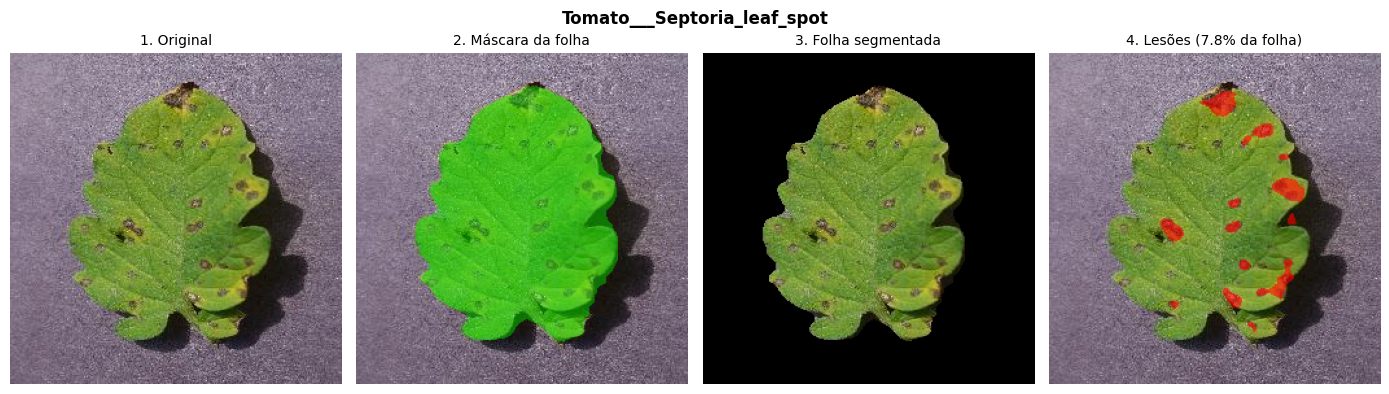

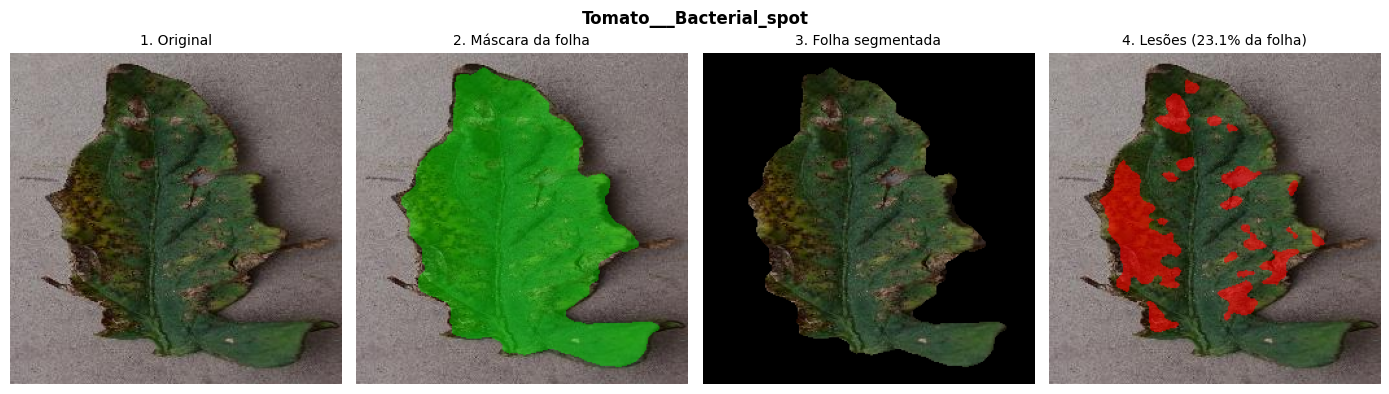

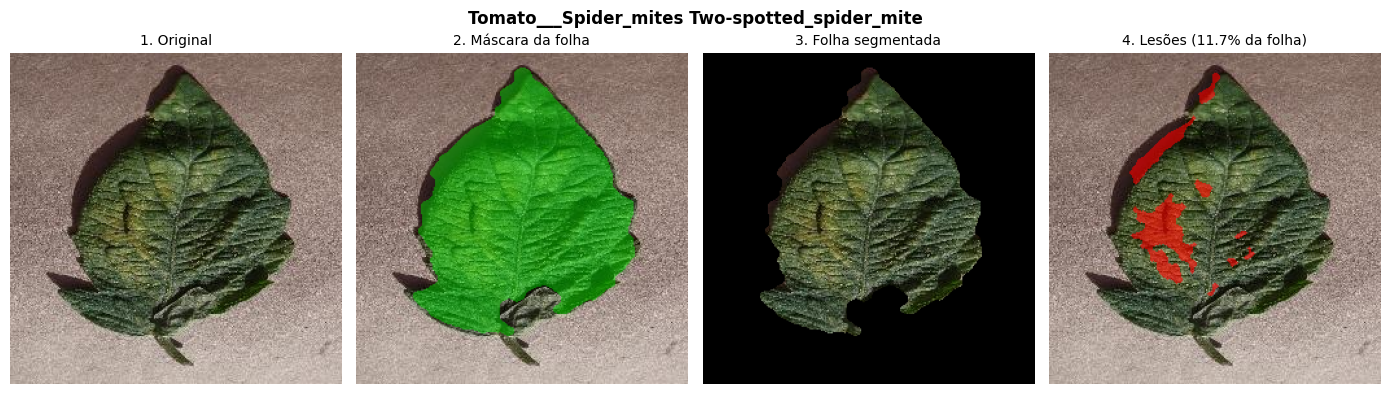

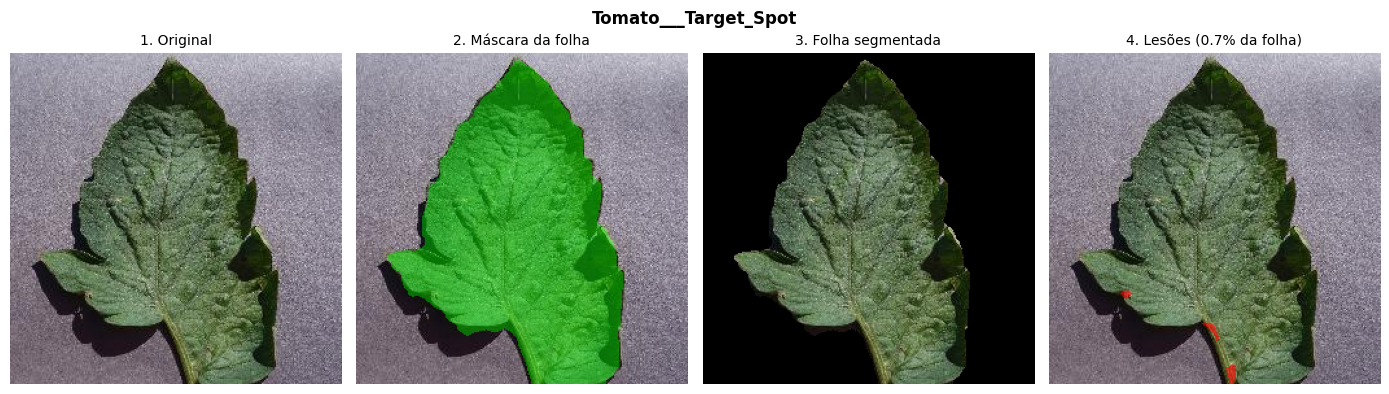

In [7]:
def overlay(bgr, mask, color=(0, 0, 255), alpha=0.5):
    out = bgr.copy()
    out[mask > 0] = (np.array(color) * alpha + out[mask > 0] * (1 - alpha)).astype(np.uint8)
    return out

def show_pipeline(res, title=""):
    bgr, leaf, lesion = res["bgr"], res["leaf_mask"], res["lesion_mask"]
    ratio = res["features"][-13]  # lesion_ratio
    panels = [("1. Original", bgr),
              ("2. Máscara da folha", overlay(bgr, leaf, (0, 255, 0), 0.4)),
              ("3. Folha segmentada", cv2.bitwise_and(bgr, bgr, mask=leaf)),
              (f"4. Lesões ({ratio*100:.1f}% da folha)", overlay(bgr, lesion, (0, 0, 255), 0.6))]
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    for ax, (t, im) in zip(axes, panels):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(t, fontsize=10); ax.axis("off")
    if title: fig.suptitle(title, weight="bold")
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
pool = [c for c in classes if "Tomato" in c] or classes
for cls in rng.choice(pool, min(4, len(pool)), replace=False):
    f = rng.choice(sorted((COLOR_DIR / cls).iterdir()))
    show_pipeline(run_pipeline(load_image(f)), cls)

## 4. Extração de features do dataset
Configure abaixo. Para o experimento principal usamos **tomate** (10 classes). `MAX_PER_CLASS = None` usa todas as imagens (mais lento); use ~300 para testar.

In [8]:
CROPS = ["Tomato"]          # ex.: ["Tomato", "Potato"]; None = todas as culturas
MAX_PER_CLASS = 500         # None = todas
EXTS = {".jpg", ".jpeg", ".png"}

def safe_extract(path):
    try: return extract_from_path(path)
    except Exception as e:
        print("[aviso]", path, e); return None

rng = np.random.default_rng(SEED)
paths, labels = [], []
for cls in classes:
    if CROPS and cls.split("___")[0].lower() not in [c.lower() for c in CROPS]: continue
    files = sorted(f for f in (COLOR_DIR / cls).iterdir() if f.suffix.lower() in EXTS)
    if MAX_PER_CLASS and len(files) > MAX_PER_CLASS:
        files = list(rng.choice(files, MAX_PER_CLASS, replace=False))
    paths += files; labels += [cls] * len(files)
print(len(paths), "imagens")

results = Parallel(n_jobs=-1, verbose=5)(delayed(safe_extract)(p) for p in paths)
keep = [i for i, r in enumerate(results) if r is not None]
X = np.vstack([results[i] for i in keep]); y_cls = np.array([labels[i] for i in keep])
names_feat = feature_names()
print("X:", X.shape, "| classes:", len(set(y_cls)))
np.savez_compressed("features.npz", X=X, y=y_cls, names=np.array(names_feat))

4873 imagens


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:    2.0s
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:    9.6s
[Parallel(n_jobs=-1)]: Done 552 tasks      | elapsed:   23.2s
[Parallel(n_jobs=-1)]: Done 1056 tasks      | elapsed:   41.6s
[Parallel(n_jobs=-1)]: Done 1704 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 2496 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 3432 tasks      | elapsed:  2.2min
[Parallel(n_jobs=-1)]: Done 4512 tasks      | elapsed:  2.9min
[Parallel(n_jobs=-1)]: Done 4873 out of 4873 | elapsed:  3.1min finished


X: (4873, 173) | classes: 10


## 5. Treino e avaliação (SVM-RBF, Random Forest e MLP)
Validação cruzada estratificada de 5 folds; métricas macro.

In [9]:
def build_models():
    pipe = lambda clf: Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    return {
        "SVM-RBF": pipe(SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced", random_state=SEED)),
        "RandomForest": pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1, class_weight="balanced", random_state=SEED)),
        "MLP": pipe(MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, early_stopping=True, random_state=SEED)),
    }

def evaluate(task):
    if task == "binary":
        y_raw = np.where(np.char.endswith(np.char.lower(y_cls.astype(str)), "healthy"), "saudavel", "doente")
    else:
        y_raw = y_cls
    le = LabelEncoder(); y = le.fit_transform(y_raw)   # inteiros: MLP com early_stopping falha com strings
    names = list(le.classes_)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    models, rows = build_models(), []
    for name, model in models.items():
        pred = cross_val_predict(model, X, y, cv=cv)
        rows.append({"modelo": name, "acuracia": accuracy_score(y, pred),
                     "precisao_macro": precision_score(y, pred, average="macro", zero_division=0),
                     "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
                     "f1_macro": f1_score(y, pred, average="macro", zero_division=0)})
        print(f"\n===== {task.upper()} | {name} =====")
        print(classification_report(y, pred, target_names=names, zero_division=0))
        size = max(5, 0.7 * len(names))
        fig, ax = plt.subplots(figsize=(size, size))
        ConfusionMatrixDisplay(confusion_matrix(y, pred, normalize="true"), display_labels=names).plot(
            ax=ax, xticks_rotation=90, colorbar=False, values_format=".2f" if len(names) <= 6 else None)
        ax.set_title(f"{name} - {task} (normalizada)"); plt.tight_layout(); plt.show()
    df = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
    best = df.loc[0, "modelo"]
    final = models[best].fit(X, y)
    return df, {"model": final, "encoder": le, "task": task, "name": best}

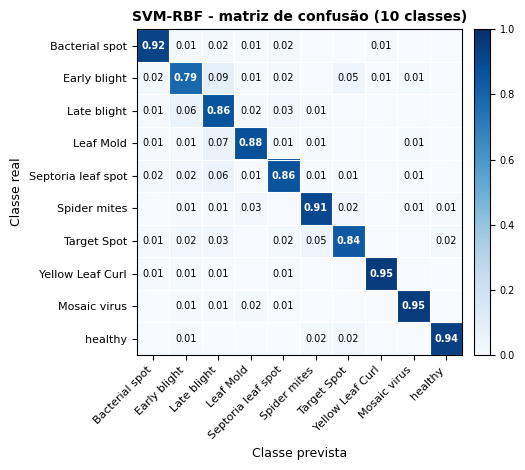

In [10]:
def nome_curto(n):
    n = n.split("___")[-1].replace("_", " ").strip()
    mapa = {"Spider mites Two-spotted spider mite": "Spider mites",
            "Tomato Yellow Leaf Curl Virus": "Yellow Leaf Curl",
            "Tomato mosaic virus": "Mosaic virus"}
    return mapa.get(n, n)

def plot_cm_artigo(y_true, y_pred, class_names, title, fname):
    names = [nome_curto(n) for n in class_names]
    cm = confusion_matrix(y_true, y_pred, normalize="true"); n = len(names)
    fig, ax = plt.subplots(figsize=(5.4, 4.8))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(names, fontsize=8)
    for i in range(n):
        for j in range(n):
            v = cm[i, j]
            if v >= 0.005:
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if v > 0.5 else "black",
                        fontweight="bold" if i == j else "normal")
    ax.set_xlabel("Classe prevista", fontsize=9); ax.set_ylabel("Classe real", fontsize=9)
    ax.set_title(title, fontsize=10, weight="bold")
    ax.set_xticks(np.arange(-.5, n, 1), minor=True); ax.set_yticks(np.arange(-.5, n, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8); ax.tick_params(which="minor", length=0)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.ax.tick_params(labelsize=7)
    plt.tight_layout(); plt.savefig(fname, dpi=300, bbox_inches="tight"); plt.show()

le_m = LabelEncoder(); y_m = le_m.fit_transform(y_cls)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pred_svm = cross_val_predict(build_models()["SVM-RBF"], X, y_m, cv=cv)
plot_cm_artigo(y_m, pred_svm, le_m.classes_, "SVM-RBF - matriz de confusão (10 classes)", "cm_svm_multiclasse.png")


===== BINARY | SVM-RBF =====
              precision    recall  f1-score   support

      doente       0.99      0.99      0.99      4373
    saudavel       0.94      0.95      0.94       500

    accuracy                           0.99      4873
   macro avg       0.96      0.97      0.97      4873
weighted avg       0.99      0.99      0.99      4873



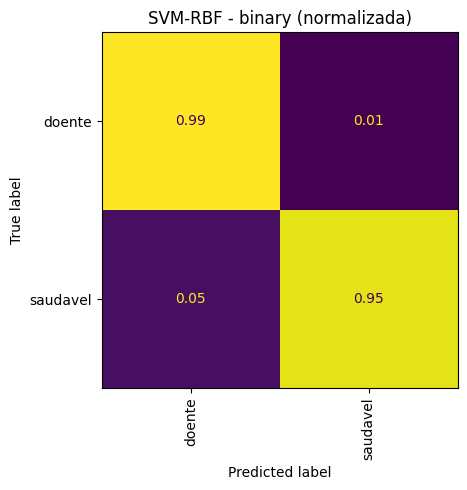


===== BINARY | RandomForest =====
              precision    recall  f1-score   support

      doente       0.98      1.00      0.99      4373
    saudavel       0.98      0.83      0.90       500

    accuracy                           0.98      4873
   macro avg       0.98      0.91      0.94      4873
weighted avg       0.98      0.98      0.98      4873



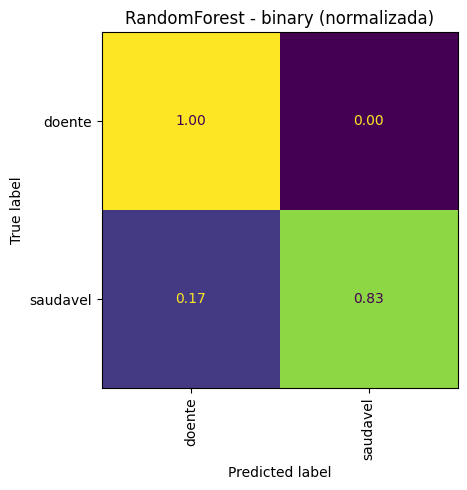


===== BINARY | MLP =====
              precision    recall  f1-score   support

      doente       0.99      0.99      0.99      4373
    saudavel       0.95      0.92      0.93       500

    accuracy                           0.99      4873
   macro avg       0.97      0.96      0.96      4873
weighted avg       0.99      0.99      0.99      4873



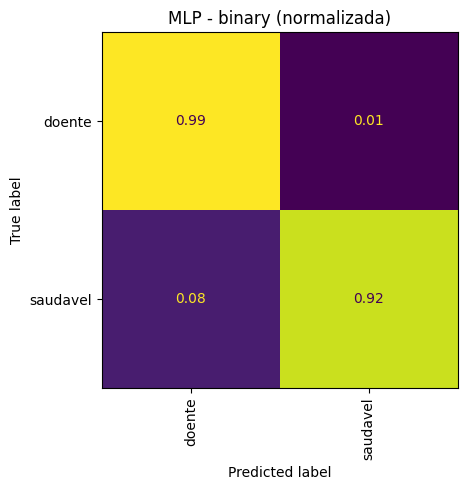

,modelo,acuracia,precisao_macro,recall_macro,f1_macro
0,SVM-RBF,0.9883,0.9648,0.9722,0.9685
1,MLP,0.9865,0.9703,0.9553,0.9626
2,RandomForest,0.9807,0.9809,0.9131,0.9437


In [11]:
df_bin, bundle_bin = evaluate("binary")
df_bin.round(4)


===== MULTICLASS | SVM-RBF =====
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.92      0.92      0.92       500
                        Tomato___Early_blight       0.82      0.79      0.81       500
                         Tomato___Late_blight       0.75      0.86      0.80       500
                           Tomato___Leaf_Mold       0.90      0.88      0.89       500
                  Tomato___Septoria_leaf_spot       0.89      0.86      0.87       500
Tomato___Spider_mites Two-spotted_spider_mite       0.89      0.91      0.90       500
                         Tomato___Target_Spot       0.88      0.84      0.86       500
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.97      0.95      0.96       500
                 Tomato___Tomato_mosaic_virus       0.94      0.95      0.95       373
                             Tomato___healthy       0.97      0.94      0.95       500

       

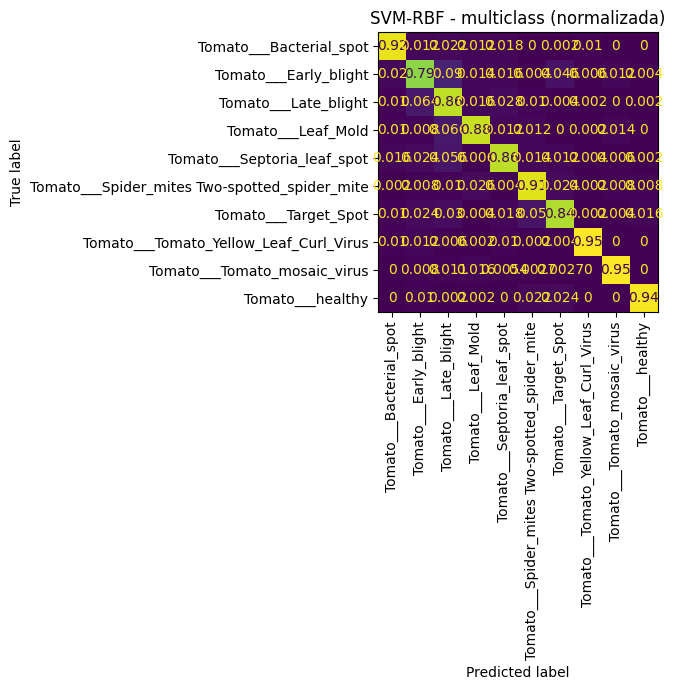


===== MULTICLASS | RandomForest =====
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.91      0.92      0.91       500
                        Tomato___Early_blight       0.81      0.78      0.80       500
                         Tomato___Late_blight       0.86      0.81      0.84       500
                           Tomato___Leaf_Mold       0.88      0.90      0.89       500
                  Tomato___Septoria_leaf_spot       0.86      0.84      0.85       500
Tomato___Spider_mites Two-spotted_spider_mite       0.80      0.87      0.83       500
                         Tomato___Target_Spot       0.81      0.84      0.82       500
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.94      0.93      0.94       500
                 Tomato___Tomato_mosaic_virus       0.94      0.99      0.97       373
                             Tomato___healthy       0.96      0.90      0.93       500

  

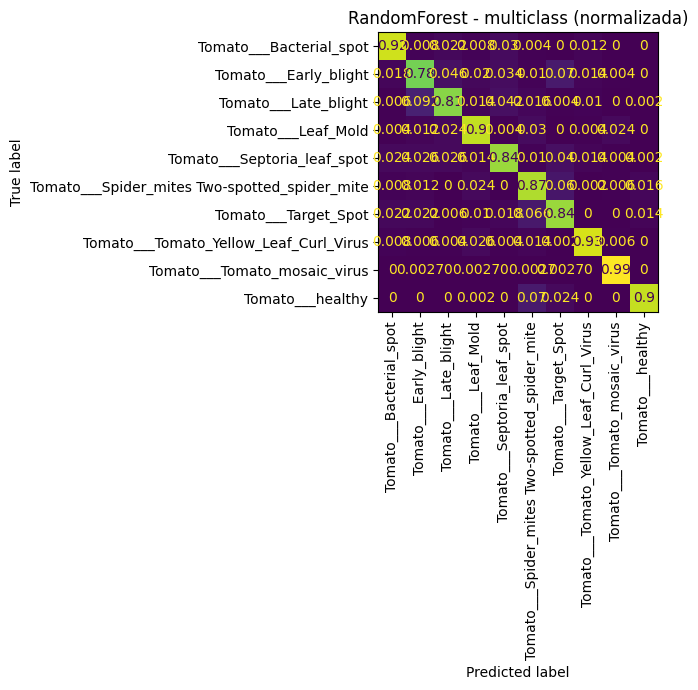


===== MULTICLASS | MLP =====
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.91      0.92      0.92       500
                        Tomato___Early_blight       0.81      0.79      0.80       500
                         Tomato___Late_blight       0.83      0.82      0.83       500
                           Tomato___Leaf_Mold       0.90      0.90      0.90       500
                  Tomato___Septoria_leaf_spot       0.85      0.86      0.86       500
Tomato___Spider_mites Two-spotted_spider_mite       0.85      0.90      0.87       500
                         Tomato___Target_Spot       0.84      0.84      0.84       500
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.96      0.95      0.95       500
                 Tomato___Tomato_mosaic_virus       0.95      0.95      0.95       373
                             Tomato___healthy       0.95      0.93      0.94       500

           

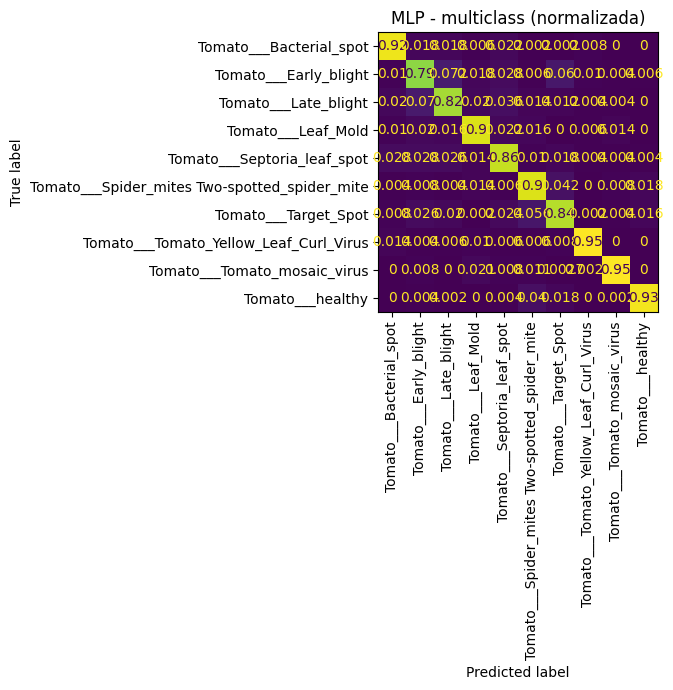

,modelo,acuracia,precisao_macro,recall_macro,f1_macro
0,SVM-RBF,0.8894,0.8929,0.8910,0.8914
1,MLP,0.8834,0.8853,0.8850,0.8850
2,RandomForest,0.8761,0.8789,0.8789,0.8784


In [12]:
df_multi, bundle_multi = evaluate("multiclass")
df_multi.round(4)

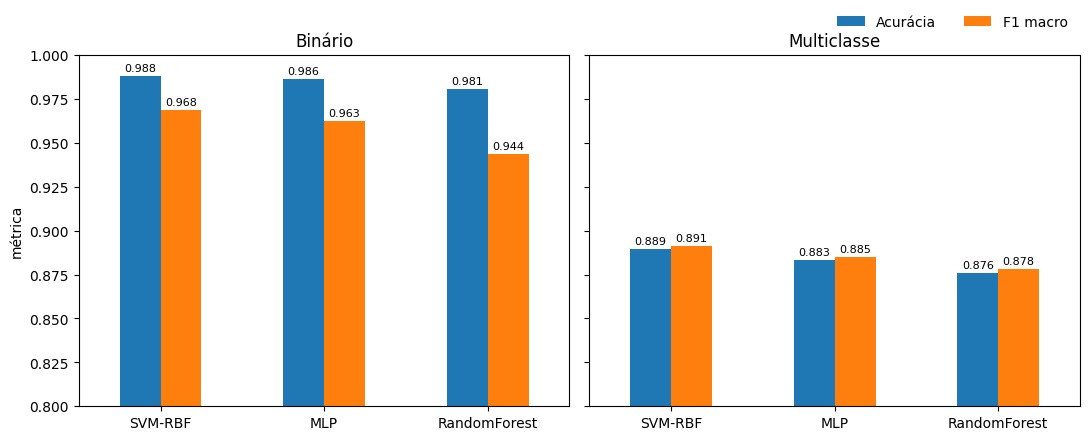

In [13]:
# Gráfico comparativo para o artigo
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (t, d) in zip(axes, [("Binário", df_bin), ("Multiclasse", df_multi)]):
    d.set_index("modelo")[["acuracia", "f1_macro"]].plot.bar(ax=ax, rot=0, ylim=(0.8, 1.0), legend=False)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    ax.set_title(t); ax.set_xlabel("")
axes[0].set_ylabel("métrica")
axes[1].legend(["Acurácia", "F1 macro"], loc="upper right", bbox_to_anchor=(1.0, 1.15), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("comparacao_modelos.png", dpi=200)
plt.show()

### Importância das features (Random Forest, multiclasse) — útil para justificar cor/textura/forma no artigo

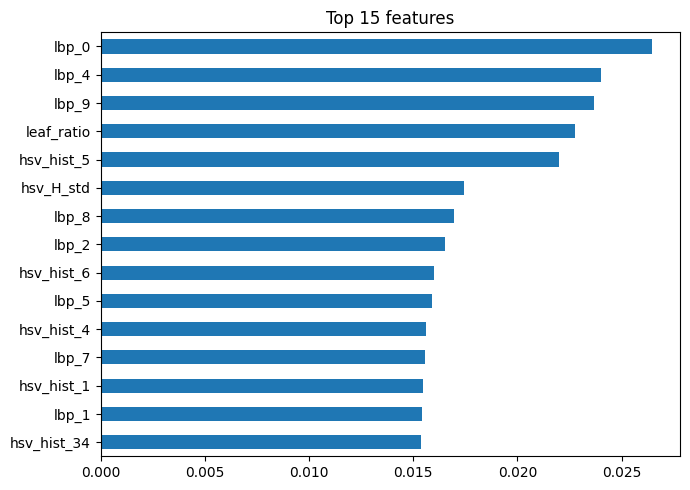

{'Cor': 0.608, 'Textura': 0.292, 'Forma': 0.1}


In [14]:
le = LabelEncoder().fit(y_cls)
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(X, le.transform(y_cls))
imp = pd.Series(rf.feature_importances_, index=names_feat).sort_values(ascending=False)
imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title="Top 15 features"); plt.tight_layout(); plt.show()
groups = {"Cor": [n for n in names_feat if n.startswith(("hsv", "lab"))],
          "Textura": [n for n in names_feat if n.startswith(("glcm", "lbp"))],
          "Forma": [n for n in names_feat if n.startswith(("lesion", "leaf", "n_spots", "mean_", "max_", "hu_"))]}
print({k: round(float(imp[v].sum()), 3) for k, v in groups.items()})

## 6. Prova de Conceito (demo)
Envie uma foto de folha (ou use uma imagem aleatória do dataset). Mostra as etapas do pipeline e a classe prevista.

Classe real: Tomato___Bacterial_spot


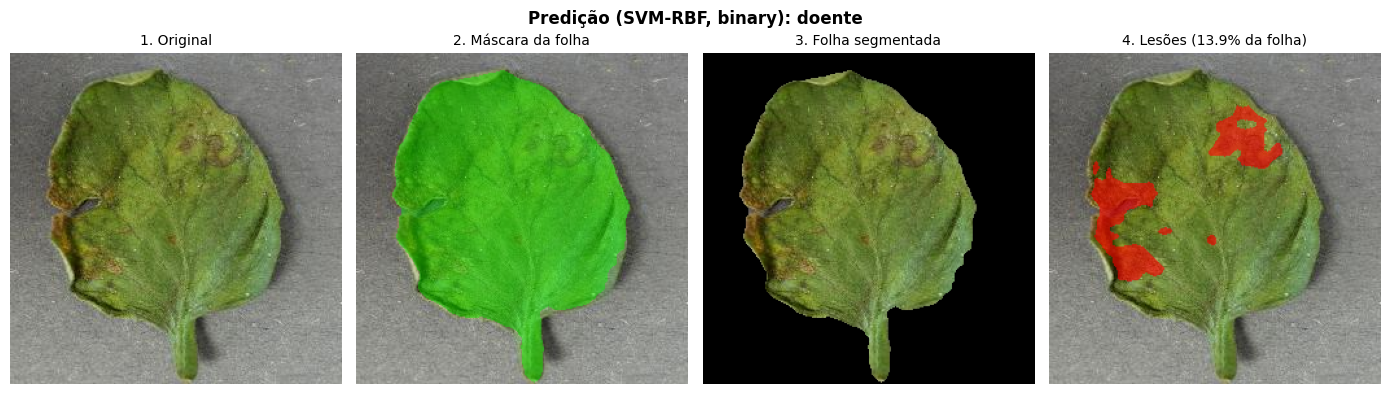

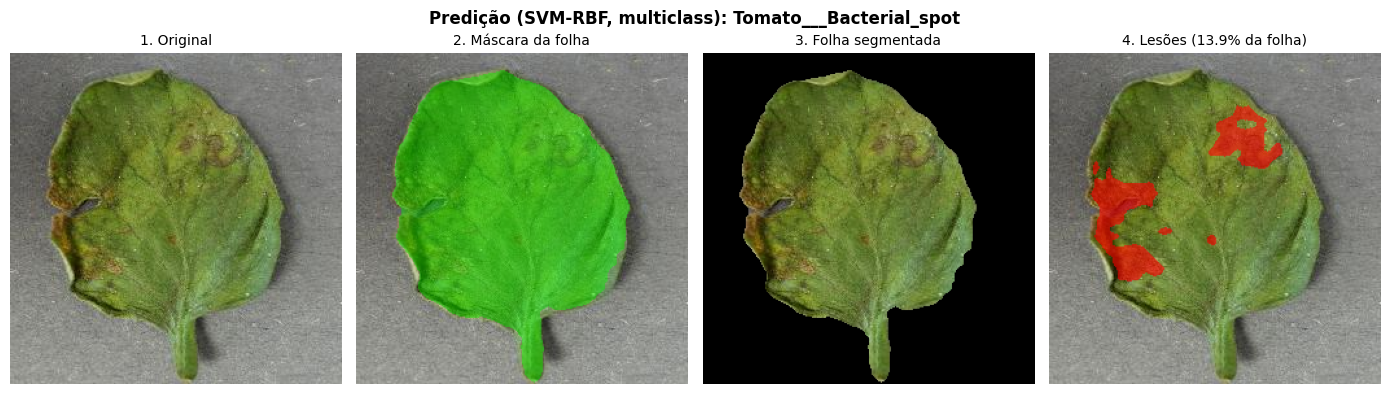

np.str_('Tomato___Bacterial_spot')

In [15]:
def predict_image(path, bundle):
    res = run_pipeline(load_image(path))
    pred = bundle["encoder"].inverse_transform(bundle["model"].predict(res["features"].reshape(1, -1)))[0]
    show_pipeline(res, f"Predição ({bundle['name']}, {bundle['task']}): {pred}")
    return pred

USE_UPLOAD = False   # False = sorteia uma imagem do dataset
if USE_UPLOAD:
    from google.colab import files
    up = files.upload()
    img_path = list(up.keys())[0]
else:
    cls = rng.choice([c for c in set(y_cls)]); img_path = rng.choice(sorted((COLOR_DIR / cls).iterdir()))
    print("Classe real:", cls)
predict_image(img_path, bundle_bin)
predict_image(img_path, bundle_multi)

## 7. Notas para o artigo
- **Vazamento de dados:** o PlantVillage tem muitas quase-duplicatas (mesma folha com rotações/flip); o split aleatório pode inflar as métricas.
- **Fundo controlado:** imagens de laboratório; pode não generalizar para fotos de campo.
- **Segmentação por limiar:** sensível a iluminação; a faixa de "verde" (`GREEN_LOW`/`GREEN_HIGH`) foi definida empiricamente.
- **Trabalhos futuros:** agrupar duplicatas na validação, testar em imagens reais, selecionar features, ajustar hiperparâmetros (GridSearch).